Import Library, Kunci Seed, dan Menyiapkan Dataset Oxford Pet

In [ ]:
# Import library dasar Python buat ngatur file, waktu, sama acak angka
import os, random, json, time
import numpy as np

# Import library PyTorch buat model deep learning
import torch
import torch.nn as nn
from torch.utils.data import DataLoader, Subset

# Import torchvision buat comot model pretrained, dataset bawaan, dan transformasi gambar
from torchvision import models, transforms, datasets

# Import scikit-learn buat bagi data seimbang (stratified) & ngitung F1-Score
from sklearn.model_selection import train_test_split
from sklearn.metrics import f1_score

# Patok random seed di angka 42 biar kalau kodenya dirun ulang, hasilnya tetep konsisten
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

# Cek GPU: Kalau Colab dapet GPU T4 pake GPU, kalau tidak harus pakai CPU.
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# Pilih 10 kelas spesifik aja dari Oxford Pet (5 ras kucing & 5 ras anjing)
selected_classes = [0, 1, 2, 3, 4, 12, 13, 14, 15, 16]

# Panggil settingan bobot pretrained ResNet-18 bawaan standar ImageNet
weights = models.ResNet18_Weights.IMAGENET1K_V1

# Ambil transformasi bawaan ImageNet (Resize 256, Crop tengah 224, terus di-normalize)
eval_transforms = weights.transforms()

# Download dataset Oxford-IIIT Pet otomatis via torchvision
full_dataset = datasets.OxfordIIITPet(root='./data', download=True, transform=eval_transforms)

# Saring khusus hanya indeks gambar yang masuk ke 10 kelas pilihan kita tadi
indices = [i for i, (_, label) in enumerate(full_dataset) if label in selected_classes]

# Ambil label asli dari gambar yang udah disaring
labels = [full_dataset[i][1] for i in indices]

# Bikin pemetaan label baru: misal label asli [0, 12, 13] diubah jadi [0, 1, 2] biar urut 0-9
label_map = {orig: new for new, orig in enumerate(selected_classes)}

# Bagi data: 70% buat Train, 30% sisa buat dipotong lagi (proporsi kelas tetep seimbang)
train_idx, test_val_idx = train_test_split(
    indices, test_size=0.3, stratify=labels, random_state=SEED
)

# Bagi 30% sisa tadi jadi dua: 15% Validation & 15% Test
val_idx, test_idx = train_test_split(
    test_val_idx, test_size=0.5,
    stratify=[labels[indices.index(i)] for i in test_val_idx],
    random_state=SEED
)

# Bikin racikan augmentasi khusus data Train (buat eksperimen B4 nanti)
train_transforms = transforms.Compose([
    transforms.Resize(256),                                # Resize gambar jadi 256x256
    transforms.RandomResizedCrop(224, scale=(0.8, 1.0)),   # Crop acak ukuran 224x224 (pangkas 80-100% area)
    transforms.RandomHorizontalFlip(p=0.5),                 # Diputer balik ke kanan-kiri (peluang 50%)
    transforms.RandomRotation(degrees=15),                 # Diputer miring acak maks 15 derajat
    transforms.ColorJitter(brightness=0.2, contrast=0.2),  # Diacak dikit kecerahan & kontrasnya
    transforms.ToTensor(),                                 # Ubah gambar jadi Tensor PyTorch
    transforms.Normalize(                                  # Di-normalize pake mean & std bawaan ImageNet
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

# Bungkus data ke DataLoader biar diproses per batch (32 gambar sekali jalan)
train_loader = DataLoader(Subset(full_dataset, train_idx), batch_size=32, shuffle=True)
val_loader = DataLoader(Subset(full_dataset, val_idx), batch_size=32, shuffle=False)
test_loader = DataLoader(Subset(full_dataset, test_idx), batch_size=32, shuffle=False)

100%|██████████| 792M/792M [00:48<00:00, 16.2MB/s]
100%|██████████| 19.2M/19.2M [00:03<00:00, 6.31MB/s]


Fungsi Tes Model & Engine Training (Ada Early Stopping-nya)

In [3]:
# Fungsi buat cek akurasi, loss, & F1-score model di data validation atau test
def evaluate(model, dataloader, criterion):
    model.eval()                         # Matikan mode training (Dropout & BatchNorm di-freeze)
    total_loss, correct, total = 0.0, 0, 0
    all_preds, all_labels = [], []       # Nampung hasil prediksi & label asli buat hitung F1-score

    with torch.no_grad():                # Matikan hitungan gradien biar GPU nggak ngejebol & lebih cepet
        for inputs, targets in dataloader:
            inputs = inputs.to(device)   # Lempar data gambar ke GPU
            # Remap label asli ke 0-9
            targets = torch.tensor([label_map[t.item()] for t in targets]).to(device)

            outputs = model(inputs)      # Tes jalanin model
            loss = criterion(outputs, targets) # Hitung seberapa salah prediksinya

            total_loss += loss.item() * inputs.size(0)
            _, predicted = outputs.max(1)              # Ambil tebakan dengan nilai paling pede
            total += targets.size(0)
            correct += predicted.eq(targets).sum().item() # Hitung berapa biji yang benar

            all_preds.extend(predicted.cpu().numpy())
            all_labels.extend(targets.cpu().numpy())

    avg_loss = total_loss / total                                    # Loss rata-rata
    accuracy = correct / total                                       # Akurasi biasa
    f1 = f1_score(all_labels, all_preds, average='macro')             # Macro F1-Score (sesuai req tugas)
    return avg_loss, accuracy, f1

# Fungsi utama buat ngelatih model per-epoch
def train_pipeline(model, train_loader, val_loader, criterion, optimizer, epochs=15, patience=3):
    best_loss = float('inf')            # Bikin nilai loss terbaik awal jadi tak hingga
    patience_cnt = 0                     # Penghitung berapa kali val loss nggak membaik
    history = {'train_loss': [], 'val_loss': [], 'val_acc': []} # Tempat nyimpen riwayat
    start_time = time.time()             # Catat jam mulai

    for epoch in range(epochs):
        model.train()                    # Nyalain mode training
        running_loss = 0.0

        for inputs, targets in train_loader:
            inputs = inputs.to(device)
            targets = torch.tensor([label_map[t.item()] for t in targets]).to(device)

            optimizer.zero_grad()        # Bersihin sisa gradien dari iterasi sebelumnya
            outputs = model(inputs)      # Jalanin model (forward propagation)
            loss = criterion(outputs, targets) # Hitung loss
            loss.backward()              # Hitung gradien (backpropagation)
            optimizer.step()             # Update bobot model

            running_loss += loss.item() * inputs.size(0)

        t_loss = running_loss / len(train_loader.dataset)           # Rata-rata loss training
        v_loss, v_acc, _ = evaluate(model, val_loader, criterion)   # Cek performa di data validation

        # Simpan metrik epoch ini
        history['train_loss'].append(t_loss)
        history['val_loss'].append(v_loss)
        history['val_acc'].append(v_acc)

        print(f"Epoch {epoch+1:02d} | Train Loss: {t_loss:.4f} | Val Loss: {v_loss:.4f} | Val Acc: {v_acc:.4f}")

        # Cek Early Stopping: kalau val_loss turun (artinya membaik), simpan modelnya
        if v_loss < best_loss:
            best_loss = v_loss
            patience_cnt = 0
            torch.save(model.state_dict(), 'best_model.pth') # Simpan bobot terbaik
        else:
            patience_cnt += 1
            if patience_cnt >= patience: # Kalau 3 epoch berturut-turut val loss gak membaik, stop!
                print("Early stopping dipicu! Biar gak overfitting.")
                break

    elapsed = time.time() - start_time  # Hitung total durasi training
    model.load_state_dict(torch.load('best_model.pth')) # Load lagi model versi paling oke
    return model, history, elapsed

Eksekusi Eksperimen B1 - B5 & Simpan File JSON

In [4]:
# Tempat nampung semua rekapan hasil eksperimen B1 sampe B5
logs_experiment = {}

# EKSPERIMEN B1: Baseline from Scratch
# Latih ResNet-18 dari nol (bobot masih acak/tanpa pretrained ImageNet)
m_b1 = models.resnet18(weights=None)
m_b1.fc = nn.Linear(m_b1.fc.in_features, 10) # Ganti ujungnya jadi 10 kelas
m_b1 = m_b1.to(device)

opt_b1 = torch.optim.AdamW(m_b1.parameters(), lr=1e-3, weight_decay=1e-2)
m_b1, h_b1, t_b1 = train_pipeline(m_b1, train_loader, val_loader, nn.CrossEntropyLoss(), opt_b1)
_, acc_b1, f1_b1 = evaluate(m_b1, test_loader, nn.CrossEntropyLoss()) # Tes ke data uji

# Simpan log metrik B1
logs_experiment['B1'] = {
    'trainable_params': sum(p.numel() for p in m_b1.parameters() if p.requires_grad),
    'epochs_converged': len(h_b1['train_loss']),
    'train_time_sec': round(t_b1, 2),
    'val_acc': round(h_b1['val_acc'][-1], 4),
    'test_macro_f1': round(f1_b1, 4)
}


# EKSPERIMEN B2: Feature Extraction
# Pake ResNet-18 pretrained, gembok (freeze) seluruh badannya, cuma latih layer fc-nya
m_b2 = models.resnet18(weights=models.ResNet18_Weights.IMAGENET1K_V1)
for p in m_b2.parameters():
    p.requires_grad = False            # Kunci semua bobot bawaan
m_b2.fc = nn.Linear(m_b2.fc.in_features, 10) # Cuma layer fc ini yang terbuka buat dilatih
m_b2 = m_b2.to(device)

opt_b2 = torch.optim.AdamW(m_b2.fc.parameters(), lr=1e-3, weight_decay=1e-2)
m_b2, h_b2, t_b2 = train_pipeline(m_b2, train_loader, val_loader, nn.CrossEntropyLoss(), opt_b2)
_, acc_b2, f1_b2 = evaluate(m_b2, test_loader, nn.CrossEntropyLoss())

logs_experiment['B2'] = {
    'trainable_params': sum(p.numel() for p in m_b2.parameters() if p.requires_grad),
    'epochs_converged': len(h_b2['train_loss']),
    'train_time_sec': round(t_b2, 2),
    'val_acc': round(h_b2['val_acc'][-1], 4),
    'test_macro_f1': round(f1_b2, 4)
}


# EKSPERIMEN B3: Progressive Fine-Tuning
# Buka gembok di blok residual terakhir (layer4) + fc, pakaikan Differential Learning Rate
m_b3 = models.resnet18(weights=models.ResNet18_Weights.IMAGENET1K_V1)
for p in m_b3.parameters():
    p.requires_grad = False            # Kunci dulu semuanya
for p in m_b3.layer4.parameters():
    p.requires_grad = True             # Buka gembok layer4
m_b3.fc = nn.Linear(m_b3.fc.in_features, 10) # Buka gembok fc
m_b3 = m_b3.to(device)

# Differential LR: Learning rate layer4 dibuat lebih kecil (1e-4) dibanding fc (1e-3) biar nggak pudar fiturnya
opt_b3 = torch.optim.AdamW([
    {"params": m_b3.layer4.parameters(), "lr": 1e-4},
    {"params": m_b3.fc.parameters(), "lr": 1e-3}
], weight_decay=1e-2)

m_b3, h_b3, t_b3 = train_pipeline(m_b3, train_loader, val_loader, nn.CrossEntropyLoss(), opt_b3)
_, acc_b3, f1_b3 = evaluate(m_b3, test_loader, nn.CrossEntropyLoss())

logs_experiment['B3'] = {
    'trainable_params': sum(p.numel() for p in m_b3.parameters() if p.requires_grad),
    'epochs_converged': len(h_b3['train_loss']),
    'train_time_sec': round(t_b3, 2),
    'val_acc': round(h_b3['val_acc'][-1], 4),
    'test_macro_f1': round(f1_b3, 4)
}


# EKSPERIMEN B4: Uji Kontrol Data Augmentation
# Jalanin ulang skenario B3, TAPI kali ini pake dataset Train yang diolesi augmentasi (train_transforms)
train_dataset_aug = datasets.OxfordIIITPet(root='./data', download=False, transform=train_transforms)
train_loader_aug = DataLoader(Subset(train_dataset_aug, train_idx), batch_size=32, shuffle=True)

m_b4 = models.resnet18(weights=models.ResNet18_Weights.IMAGENET1K_V1)
for p in m_b4.parameters(): p.requires_grad = False
for p in m_b4.layer4.parameters(): p.requires_grad = True
m_b4.fc = nn.Linear(m_b4.fc.in_features, 10)
m_b4 = m_b4.to(device)

opt_b4 = torch.optim.AdamW([
    {"params": m_b4.layer4.parameters(), "lr": 1e-4},
    {"params": m_b4.fc.parameters(), "lr": 1e-3}
], weight_decay=1e-2)

# Latih ulang pake train_loader_aug
m_b4, h_b4, t_b4 = train_pipeline(m_b4, train_loader_aug, val_loader, nn.CrossEntropyLoss(), opt_b4)
_, acc_b4, f1_b4 = evaluate(m_b4, test_loader, nn.CrossEntropyLoss())

logs_experiment['B4'] = {
    'trainable_params': sum(p.numel() for p in m_b4.parameters() if p.requires_grad),
    'epochs_converged': len(h_b4['train_loss']),
    'train_time_sec': round(t_b4, 2),
    'val_acc': round(h_b4['val_acc'][-1], 4),
    'test_macro_f1': round(f1_b4, 4)
}


# EKSPERIMEN B5: Arsitektur Pembanding (EfficientNet-B0)
# Pake arsitektur EfficientNet-B0 pretrained sebagai pembanding ResNet-18
m_b5 = models.efficientnet_b0(weights=models.EfficientNet_B0_Weights.DEFAULT)
for p in m_b5.parameters():
    p.requires_grad = False            # Freeze backbone
m_b5.classifier[1] = nn.Linear(m_b5.classifier[1].in_features, 10) # Ganti layer klasifikasi
m_b5 = m_b5.to(device)

opt_b5 = torch.optim.AdamW(m_b5.classifier.parameters(), lr=1e-3, weight_decay=1e-2)
m_b5, h_b5, t_b5 = train_pipeline(m_b5, train_loader, val_loader, nn.CrossEntropyLoss(), opt_b5)
_, acc_b5, f1_b5 = evaluate(m_b5, test_loader, nn.CrossEntropyLoss())

logs_experiment['B5'] = {
    'trainable_params': sum(p.numel() for p in m_b5.parameters() if p.requires_grad),
    'epochs_converged': len(h_b5['train_loss']),
    'train_time_sec': round(t_b5, 2),
    'val_acc': round(h_b5['val_acc'][-1], 4),
    'test_macro_f1': round(f1_b5, 4)
}


# SIMPAN SEMUA LOG HASIL METRIK KE FILE JSON
# Ini bukti wajib buat dilampirin sesuai petunjuk tugas!
with open('metrics_log.json', 'w') as f:
    json.dump(logs_experiment, f, indent=4)

print("Sip, semua eksperimen B1 sampe B5 beres dikerjain!")
print("File 'metrics_log.json' udah siap dikumpulin bareng ZIP.")

Epoch 01 | Train Loss: 2.5386 | Val Loss: 11.8649 | Val Acc: 0.0940
Epoch 02 | Train Loss: 2.1807 | Val Loss: 2.6893 | Val Acc: 0.1544
Epoch 03 | Train Loss: 2.0684 | Val Loss: 2.6315 | Val Acc: 0.1477
Epoch 04 | Train Loss: 1.9791 | Val Loss: 2.9688 | Val Acc: 0.1611
Epoch 05 | Train Loss: 1.9129 | Val Loss: 2.3460 | Val Acc: 0.2483
Epoch 06 | Train Loss: 1.8386 | Val Loss: 2.4156 | Val Acc: 0.1879
Epoch 07 | Train Loss: 1.7143 | Val Loss: 2.3005 | Val Acc: 0.2550
Epoch 08 | Train Loss: 1.7095 | Val Loss: 2.1058 | Val Acc: 0.2550
Epoch 09 | Train Loss: 1.5988 | Val Loss: 3.0456 | Val Acc: 0.2081
Epoch 10 | Train Loss: 1.5820 | Val Loss: 3.1714 | Val Acc: 0.1208
Epoch 11 | Train Loss: 1.4144 | Val Loss: 2.0921 | Val Acc: 0.2886
Epoch 12 | Train Loss: 1.2962 | Val Loss: 2.3841 | Val Acc: 0.2483
Epoch 13 | Train Loss: 1.2393 | Val Loss: 2.3065 | Val Acc: 0.3154
Epoch 14 | Train Loss: 1.1416 | Val Loss: 2.4949 | Val Acc: 0.3087
Early stopping dipicu! Biar gak overfitting.
Downloading: "ht

100%|██████████| 44.7M/44.7M [00:00<00:00, 159MB/s]


Epoch 01 | Train Loss: 1.8036 | Val Loss: 1.2163 | Val Acc: 0.7852
Epoch 02 | Train Loss: 0.9751 | Val Loss: 0.7439 | Val Acc: 0.8725
Epoch 03 | Train Loss: 0.6299 | Val Loss: 0.5459 | Val Acc: 0.8993
Epoch 04 | Train Loss: 0.4673 | Val Loss: 0.4604 | Val Acc: 0.8993
Epoch 05 | Train Loss: 0.4034 | Val Loss: 0.4023 | Val Acc: 0.9195
Epoch 06 | Train Loss: 0.3425 | Val Loss: 0.3742 | Val Acc: 0.9195
Epoch 07 | Train Loss: 0.3061 | Val Loss: 0.3152 | Val Acc: 0.9128
Epoch 08 | Train Loss: 0.2464 | Val Loss: 0.2995 | Val Acc: 0.9396
Epoch 09 | Train Loss: 0.2330 | Val Loss: 0.2768 | Val Acc: 0.9262
Epoch 10 | Train Loss: 0.2224 | Val Loss: 0.2622 | Val Acc: 0.9195
Epoch 11 | Train Loss: 0.2052 | Val Loss: 0.2592 | Val Acc: 0.9262
Epoch 12 | Train Loss: 0.1857 | Val Loss: 0.2530 | Val Acc: 0.9195
Epoch 13 | Train Loss: 0.1697 | Val Loss: 0.2413 | Val Acc: 0.9396
Epoch 14 | Train Loss: 0.1630 | Val Loss: 0.2372 | Val Acc: 0.9329
Epoch 15 | Train Loss: 0.1493 | Val Loss: 0.2261 | Val Acc: 0.

100%|██████████| 20.5M/20.5M [00:00<00:00, 96.0MB/s]


Epoch 01 | Train Loss: 1.8620 | Val Loss: 1.3070 | Val Acc: 0.7785
Epoch 02 | Train Loss: 1.0887 | Val Loss: 0.8733 | Val Acc: 0.8389
Epoch 03 | Train Loss: 0.7557 | Val Loss: 0.6598 | Val Acc: 0.8792
Epoch 04 | Train Loss: 0.5565 | Val Loss: 0.5539 | Val Acc: 0.8792
Epoch 05 | Train Loss: 0.4818 | Val Loss: 0.4918 | Val Acc: 0.8993
Epoch 06 | Train Loss: 0.4052 | Val Loss: 0.4363 | Val Acc: 0.9060
Epoch 07 | Train Loss: 0.3643 | Val Loss: 0.3975 | Val Acc: 0.9128
Epoch 08 | Train Loss: 0.3311 | Val Loss: 0.3679 | Val Acc: 0.9262
Epoch 09 | Train Loss: 0.2901 | Val Loss: 0.3459 | Val Acc: 0.9396
Epoch 10 | Train Loss: 0.2737 | Val Loss: 0.3376 | Val Acc: 0.9396
Epoch 11 | Train Loss: 0.2333 | Val Loss: 0.3030 | Val Acc: 0.9463
Epoch 12 | Train Loss: 0.2292 | Val Loss: 0.3204 | Val Acc: 0.9329
Epoch 13 | Train Loss: 0.2139 | Val Loss: 0.3085 | Val Acc: 0.9329
Epoch 14 | Train Loss: 0.1967 | Val Loss: 0.2816 | Val Acc: 0.9396
Epoch 15 | Train Loss: 0.1678 | Val Loss: 0.2830 | Val Acc: 0.

Visualisasi & Failure Analysis

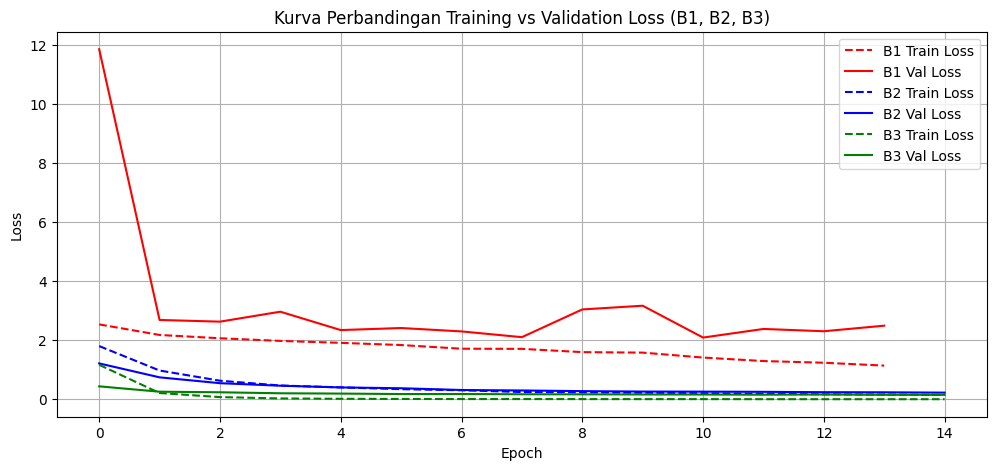

Grafik 'loss_curves.png' berhasil dibuat!


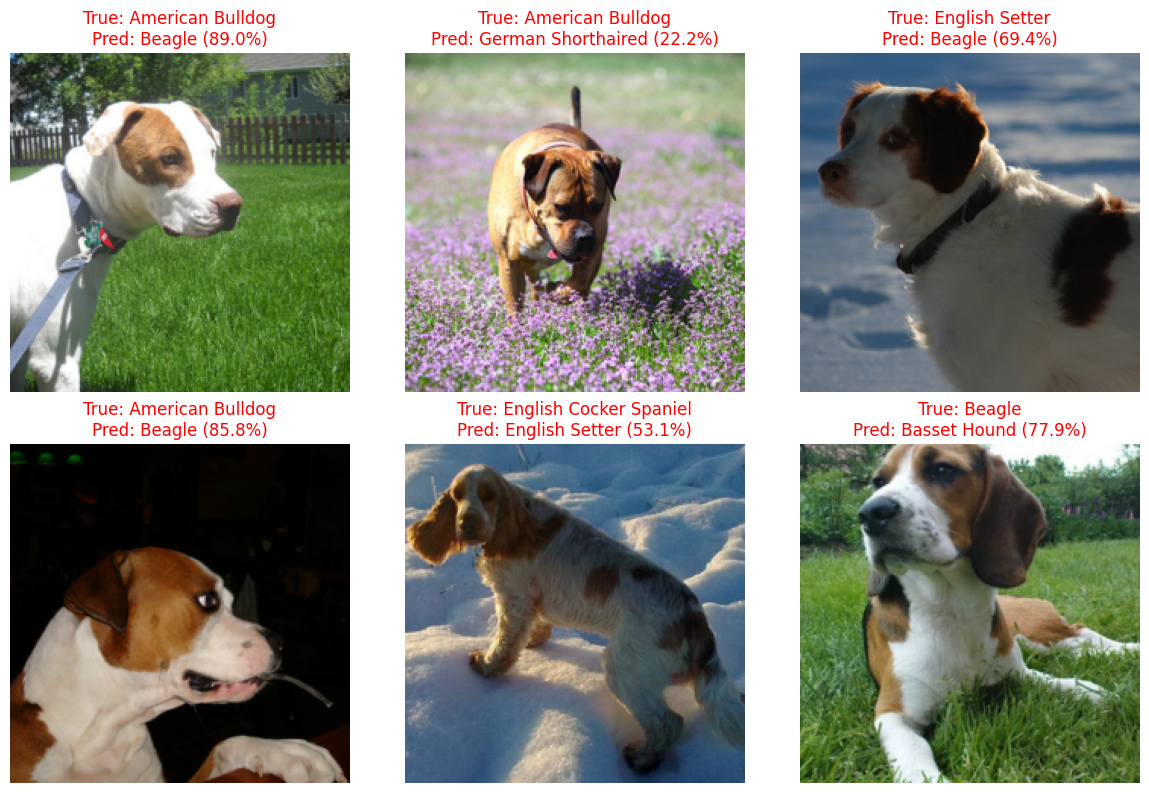

Gambar 'failure_analysis.png' berhasil dibuat!


In [5]:
import matplotlib.pyplot as plt

# 1. GRAFIK KOMPARATIF KURVA LOSS (Untuk Laporan C1)
plt.figure(figsize=(12, 5))

# Plot B1 (From Scratch)
plt.plot(h_b1['train_loss'], label='B1 Train Loss', linestyle='--', color='red')
plt.plot(h_b1['val_loss'], label='B1 Val Loss', color='red')

# Plot B2 (Feature Extraction)
plt.plot(h_b2['train_loss'], label='B2 Train Loss', linestyle='--', color='blue')
plt.plot(h_b2['val_loss'], label='B2 Val Loss', color='blue')

# Plot B3 (Fine-Tuning)
plt.plot(h_b3['train_loss'], label='B3 Train Loss', linestyle='--', color='green')
plt.plot(h_b3['val_loss'], label='B3 Val Loss', color='green')

plt.title('Kurva Perbandingan Training vs Validation Loss (B1, B2, B3)')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.grid(True)
plt.savefig('loss_curves.png') # Otomatis tersimpan jadi gambar buat dimasukkan ke laporan
plt.show()

print("Grafik 'loss_curves.png' berhasil dibuat!")


# FAILURE ANALYSIS (Untuk Laporan C3)
# Ambil model B3 (atau B4) buat dicari kesalahan prediksinya di test set
m_b3.eval()
wrong_samples = []

# Nama-nama ras kelas Oxford Pet yang dipiliha
class_names = [full_dataset.classes[c] for c in selected_classes]

with torch.no_grad():
    for inputs, targets in test_loader:
        inputs = inputs.to(device)
        targets_remapped = torch.tensor([label_map[t.item()] for t in targets]).to(device)

        outputs = m_b3(inputs)
        probs = torch.softmax(outputs, dim=1)
        confidences, preds = torch.max(probs, dim=1)

        for i in range(inputs.size(0)):
            if preds[i] != targets_remapped[i]:
                wrong_samples.append({
                    'image': inputs[i].cpu(),
                    'true_label': class_names[targets_remapped[i].item()],
                    'pred_label': class_names[preds[i].item()],
                    'confidence': confidences[i].item()
                })
            if len(wrong_samples) >= 6: # Cukup ambil 6 sampel aja
                break
        if len(wrong_samples) >= 6:
            break

# Plot 6 sampel gambar yang salah diprediksi
fig, axes = plt.subplots(2, 3, figsize=(12, 8))
for idx, sample in enumerate(wrong_samples):
    ax = axes[idx // 3, idx % 3]
    # Denormalize gambar biar warnanya normal lagi saat ditampilkan
    img = sample['image'].numpy().transpose((1, 2, 0))
    mean = np.array([0.485, 0.456, 0.406])
    std = np.array([0.229, 0.224, 0.225])
    img = std * img + mean
    img = np.clip(img, 0, 1)

    ax.imshow(img)
    ax.set_title(f"True: {sample['true_label']}\nPred: {sample['pred_label']} ({sample['confidence']*100:.1f}%)", color='red')
    ax.axis('off')

plt.tight_layout()
plt.savefig('failure_analysis.png') # Tersimpan otomatis
plt.show()

print("Gambar 'failure_analysis.png' berhasil dibuat!")